In [10]:
!pip install plotly pandas matplotlib seaborn

In [11]:
import json
import pandas as pd

with open('checkov_results.json') as f:
    data = json.load(f)

results = data if isinstance(data, list) else [data]
failed_all = []
passed_all = []
for r in results:
    failed_all += r.get('results', {}).get('failed_checks', [])
    passed_all += r.get('results', {}).get('passed_checks', [])

print(f"✅ Data loaded successfully")
print(f"📊 Total FAILED checks : {len(failed_all)}")
print(f"✅ Total PASSED checks : {len(passed_all)}")
print(f"🔑 Unique policy IDs   : {len(set(c['check_id'] for c in failed_all))}")
print(f"📁 Files analysed      : {len(set(c['file_path'].split('/')[-1] for c in failed_all))}")

✅ Data loaded successfully
📊 Total FAILED checks : 221
✅ Total PASSED checks : 0
🔑 Unique policy IDs   : 98
📁 Files analysed      : 17


In [12]:
def categorise(check_id, check_name, filename):
    c = check_id.upper()
    n = check_name.upper()
    f = filename.upper()
    if 'SECRET' in c or ('HARD' in n and 'SECRET' in n):
        return 'Hardcoded Secrets'
    if 'IAM' in f or any(x in n for x in ['IAM POLICY','IAM ROLE','PRIVILEGE',
                                            'CREDENTIALS EXPOSURE','PERMISSION']):
        return 'IAM Over-permissioning'
    if 'S3' in c and any(x in n for x in ['PUBLIC','BLOCK','ACL']):
        return 'Publicly Exposed Storage'
    if 'S3' in c or 'S3' in f:
        return 'Storage Configuration'
    if any(x in n for x in ['ENCRYPT','KMS','CMK','ENCRYPTED']):
        return 'Encryption at Rest'
    if any(x in n for x in ['INGRESS','EGRESS','SECURITY GROUP','VPC',
                              'SUBNET','PORT 22','PORT 80','0.0.0.0']):
        return 'Network Exposure'
    if any(x in n for x in ['LOG','LOGGING','MONITORING','CLOUDTRAIL',
                              'CLOUDWATCH','AUDIT','TRACING']):
        return 'Logging & Monitoring'
    if 'LAMBDA' in f or 'LAMBDA' in n:
        return 'Lambda/Serverless'
    if any(x in n for x in ['BACKUP','DELETION PROTECTION','MULTI-AZ','MINOR UPGRADE']):
        return 'Availability & Resilience'
    if 'DOCKER' in c:
        return 'Container Security'
    return 'Other'

rows = []
for c in failed_all:
    fname = c['file_path'].replace('\\', '/').split('/')[-1]
    cat = categorise(c['check_id'], c['check_name'], fname)
    rows.append({
        'check_id':   c['check_id'],
        'check_name': c['check_name'],
        'file':       fname,
        'category':   cat,
        'resource':   c.get('resource', 'N/A'),
    })

df = pd.DataFrame(rows)
print(f"✅ DataFrame built — {len(df)} rows")
df.head()

✅ DataFrame built — 221 rows


,check_id,check_name,file,category,resource
0,CKV_AWS_133,Ensure that RDS instances has backup policy,db-app.tf,Availability & Resilience,aws_db_instance.default
1,CKV_AWS_129,Ensure that respective logs of Amazon Relation...,db-app.tf,Logging & Monitoring,aws_db_instance.default
2,CKV_AWS_226,Ensure DB instance gets all minor upgrades aut...,db-app.tf,Availability & Resilience,aws_db_instance.default
3,CKV_AWS_16,Ensure all data stored in the RDS is securely ...,db-app.tf,Encryption at Rest,aws_db_instance.default
4,CKV_AWS_118,Ensure that enhanced monitoring is enabled for...,db-app.tf,Logging & Monitoring,aws_db_instance.default


In [13]:
cat_summary = df.groupby('category').size().reset_index(name='count')
cat_summary['percentage'] = (cat_summary['count'] / len(df) * 100).round(1)
cat_summary = cat_summary.sort_values('count', ascending=False).reset_index(drop=True)
cat_summary.index += 1

file_summary = df.groupby('file').size().reset_index(name='count')
file_summary['percentage'] = (file_summary['count'] / len(df) * 100).round(1)
file_summary = file_summary.sort_values('count', ascending=False).reset_index(drop=True)
file_summary.index += 1

print("=== Findings by Category ===")
display(cat_summary)
print("\n=== Findings by File ===")
display(file_summary)

=== Findings by Category ===


,category,count,percentage
1,Other,55,24.9
2,Encryption at Rest,37,16.7
3,Storage Configuration,31,14.0
4,Logging & Monitoring,29,13.1
5,Availability & Resilience,25,11.3
6,Network Exposure,19,8.6
7,IAM Over-permissioning,12,5.4
8,Hardcoded Secrets,7,3.2
9,Lambda/Serverless,4,1.8
10,Container Security,2,0.9



=== Findings by File ===


,file,count,percentage
1,rds.tf,82,37.1
2,s3.tf,31,14.0
3,ec2.tf,25,11.3
4,db-app.tf,24,10.9
5,es.tf,14,6.3
6,lambda.tf,9,4.1
7,neptune.tf,9,4.1
8,eks.tf,8,3.6
9,iam.tf,7,3.2
10,ecr.tf,3,1.4


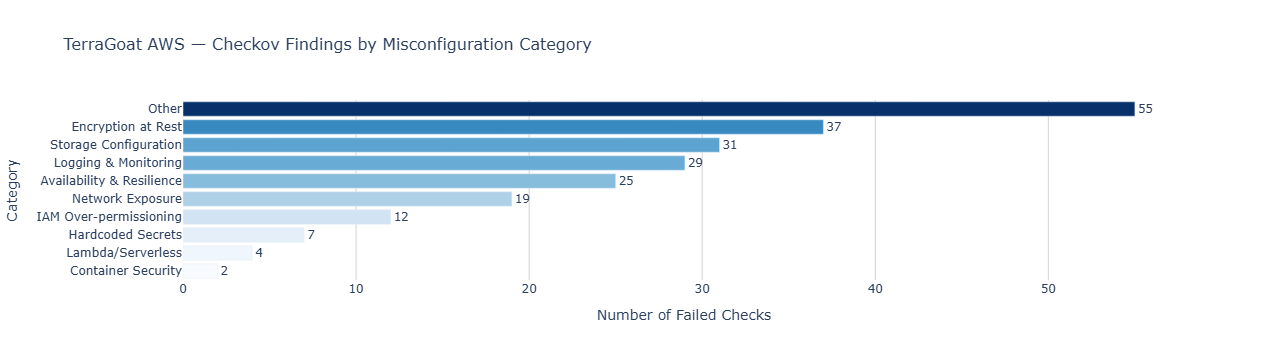

✅ Saved chart_by_category.html


In [14]:
import plotly.express as px

fig1 = px.bar(
    cat_summary.sort_values('count'),
    x='count',
    y='category',
    orientation='h',
    text='count',
    color='count',
    color_continuous_scale='Blues',
    title='TerraGoat AWS — Checkov Findings by Misconfiguration Category',
    labels={'count': 'Number of Failed Checks', 'category': 'Category'}
)
fig1.update_traces(textposition='outside')
fig1.update_layout(
    height=500,
    coloraxis_showscale=False,
    plot_bgcolor='white',
    title_font_size=16,
    xaxis=dict(showgrid=True, gridcolor='lightgrey')
)
fig1.show()
fig1.write_html("chart_by_category.html")
print("✅ Saved chart_by_category.html")

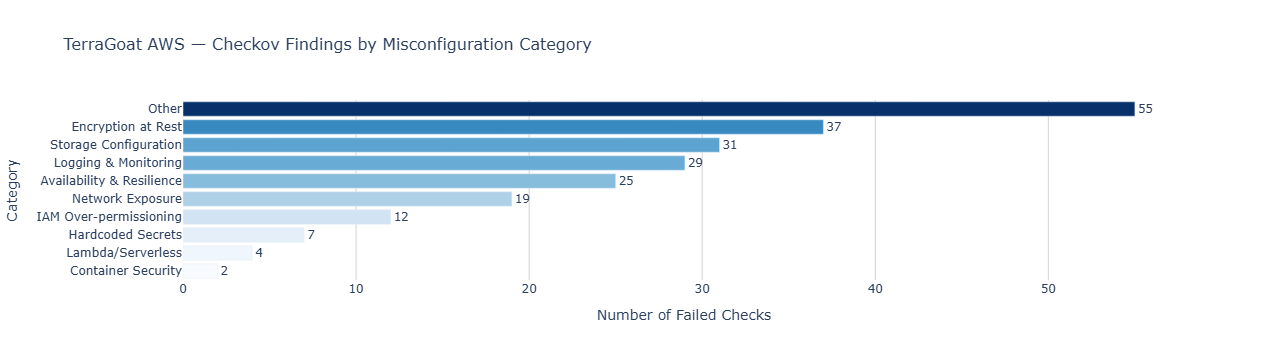

ValueError: 
The orca executable is required to export figures as static images,
but it could not be found on the system path.

Searched for executable 'orca' on the following path:
    C:\Users\lenovo\anaconda3
    C:\Users\lenovo\anaconda3\Library\mingw-w64\bin
    C:\Users\lenovo\anaconda3\Library\usr\bin
    C:\Users\lenovo\anaconda3\Library\bin
    C:\Users\lenovo\anaconda3\Scripts
    C:\Users\lenovo\anaconda3\bin
    C:\Users\lenovo\anaconda3\condabin
    D:\app\oracle\product\11.2.0\server\bin
    C:\Python310\Scripts
    C:\Python310
    C:\Windows\system32
    C:\Windows
    C:\Windows\System32\Wbem
    C:\Windows\System32\WindowsPowerShell\v1.0
    C:\Windows\System32\OpenSSH
    C:\Program Files (x86)\NVIDIA Corporation\PhysX\Common
    C:\Program Files (x86)\mingw-w64\i686-8.1.0-posix-dwarf-rt_v6-rev0\mingw32\bin
    C:\WINDOWS\system32
    C:\WINDOWS
    C:\WINDOWS\System32\Wbem
    C:\WINDOWS\System32\WindowsPowerShell\v1.0
    C:\WINDOWS\System32\OpenSSH
    C:\Program 

In [9]:
import plotly.express as px
import matplotlib.pyplot as plt
import io
from PIL import Image

fig = px.bar(
    cat_summary.sort_values('count'),
    x='count',
    y='category',
    orientation='h',
    text='count',
    color='count',
    color_continuous_scale='Blues',
    title='TerraGoat AWS — Checkov Findings by Misconfiguration Category',
    labels={'count': 'Number of Failed Checks', 'category': 'Category'}
)
fig.update_traces(textposition='outside')
fig.update_layout(
    height=500,
    coloraxis_showscale=False,
    plot_bgcolor='white',
    title_font_size=16,
    xaxis=dict(showgrid=True, gridcolor='lightgrey')
)
fig.show()

# Save using matplotlib instead of kaleido
img_bytes = fig.to_image(format="png", scale=2, engine="orca")

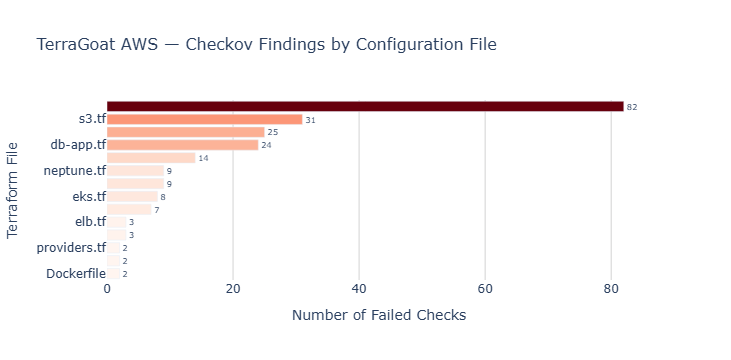

✅ Saved chart_by_file.html


In [15]:
fig2 = px.bar(
    file_summary.sort_values('count'),
    x='count',
    y='file',
    orientation='h',
    text='count',
    color='count',
    color_continuous_scale='Reds',
    title='TerraGoat AWS — Checkov Findings by Configuration File',
    labels={'count': 'Number of Failed Checks', 'file': 'Terraform File'}
)
fig2.update_traces(textposition='outside')
fig2.update_layout(
    height=500,
    coloraxis_showscale=False,
    plot_bgcolor='white',
    title_font_size=16,
    xaxis=dict(showgrid=True, gridcolor='lightgrey')
)
fig2.show()
fig2.write_html("chart_by_file.html")
print("✅ Saved chart_by_file.html")

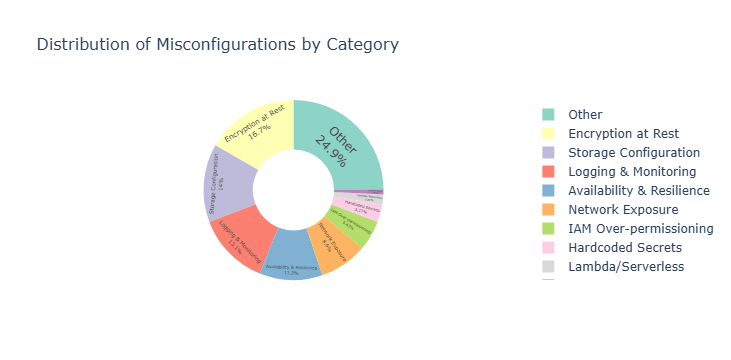

✅ Saved chart_donut_category.html


In [16]:
fig3 = px.pie(
    cat_summary,
    values='count',
    names='category',
    title='Distribution of Misconfigurations by Category',
    hole=0.45,
    color_discrete_sequence=px.colors.qualitative.Set3
)
fig3.update_traces(textposition='inside', textinfo='percent+label')
fig3.update_layout(
    height=550,
    title_font_size=16,
    legend=dict(orientation='v', x=1.05)
)
fig3.show()
fig3.write_html("chart_donut_category.html")
print("✅ Saved chart_donut_category.html")

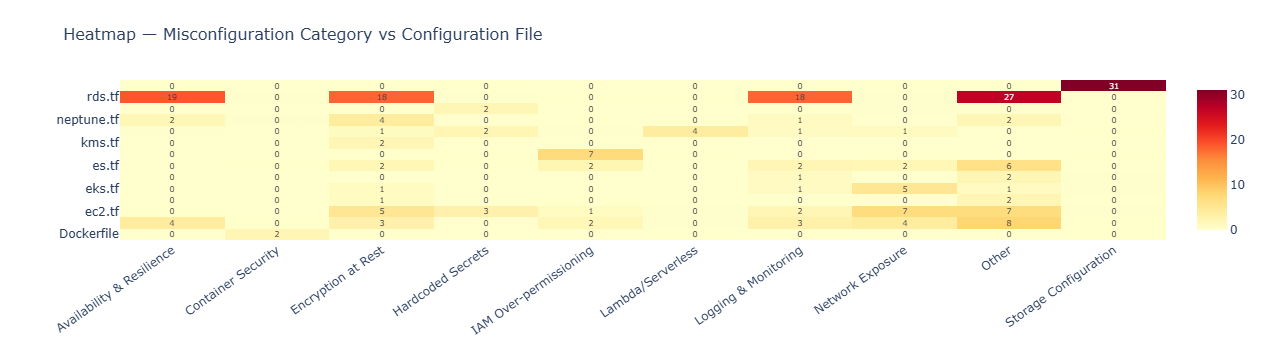

✅ Saved chart_heatmap.html


In [17]:
import plotly.graph_objects as go

heatmap_df = df.groupby(['file', 'category']).size().unstack(fill_value=0)

fig4 = go.Figure(data=go.Heatmap(
    z=heatmap_df.values,
    x=heatmap_df.columns.tolist(),
    y=heatmap_df.index.tolist(),
    colorscale='YlOrRd',
    text=heatmap_df.values,
    texttemplate="%{text}",
    showscale=True
))
fig4.update_layout(
    title='Heatmap — Misconfiguration Category vs Configuration File',
    height=550,
    title_font_size=16,
    xaxis=dict(tickangle=-35),
    margin=dict(l=120, r=40, t=80, b=120)
)
fig4.show()
fig4.write_html("chart_heatmap.html")
print("✅ Saved chart_heatmap.html")

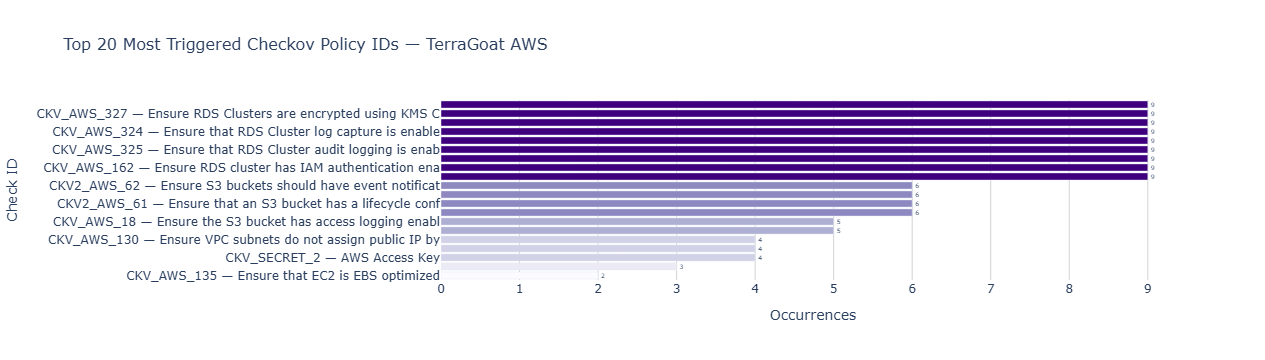

✅ Saved chart_top_checks.html


In [18]:
top_checks = (
    df.groupby(['check_id', 'check_name'])
    .size()
    .reset_index(name='count')
    .sort_values('count', ascending=False)
    .head(20)
)
top_checks['label'] = top_checks['check_id'] + ' — ' + top_checks['check_name'].str[:45]

fig5 = px.bar(
    top_checks.sort_values('count'),
    x='count',
    y='label',
    orientation='h',
    text='count',
    color='count',
    color_continuous_scale='Purples',
    title='Top 20 Most Triggered Checkov Policy IDs — TerraGoat AWS',
    labels={'count': 'Occurrences', 'label': 'Check ID'}
)
fig5.update_traces(textposition='outside')
fig5.update_layout(
    height=650,
    coloraxis_showscale=False,
    plot_bgcolor='white',
    title_font_size=16,
    xaxis=dict(showgrid=True, gridcolor='lightgrey'),
    margin=dict(l=400)
)
fig5.show()
fig5.write_html("chart_top_checks.html")
print("✅ Saved chart_top_checks.html")

In [19]:
total = len(df)
unique_ids = df['check_id'].nunique()
files = df['file'].nunique()
top_cat = cat_summary.iloc[0]['category']
top_file = file_summary.iloc[0]['file']

print("=" * 55)
print("       TERRAGOAT AWS — CHECKOV ANALYSIS SUMMARY")
print("=" * 55)
print(f"  Total failed checks       : {total}")
print(f"  Unique policy IDs         : {unique_ids}")
print(f"  Configuration files       : {files}")
print(f"  Top category              : {top_cat}")
print(f"  Most vulnerable file      : {top_file} ({file_summary.iloc[0]['count']} failures)")
print(f"  Analysis tool             : Checkov v3.3.9")
print(f"  Dataset                   : TerraGoat AWS Module")
print(f"  Ground truth status       : Checkov only (Trivy pending)")
print("=" * 55)

       TERRAGOAT AWS — CHECKOV ANALYSIS SUMMARY
  Total failed checks       : 221
  Unique policy IDs         : 98
  Configuration files       : 14
  Top category              : Other
  Most vulnerable file      : rds.tf (82 failures)
  Analysis tool             : Checkov v3.3.9
  Dataset                   : TerraGoat AWS Module
  Ground truth status       : Checkov only (Trivy pending)


In [20]:
with open('trivy_results.json') as f:
    trivy_data = json.load(f)

# Trivy structure: Results array, each with Misconfigurations array
trivy_findings = []
for result in trivy_data.get('Results', []):
    for misc in result.get('Misconfigurations', []):
        trivy_findings.append({
            'check_id':   misc.get('ID', ''),
            'check_name': misc.get('Title', ''),
            'file':       result.get('Target', '').replace('\\', '/').split('/')[-1],
            'severity':   misc.get('Severity', 'UNKNOWN'),
            'status':     misc.get('Status', ''),
        })

trivy_df = pd.DataFrame(trivy_findings)

# Keep only failed checks
trivy_failed = trivy_df[trivy_df['status'] == 'FAIL'].copy()

print(f"✅ Trivy results loaded")
print(f"📊 Total Trivy findings  : {len(trivy_df)}")
print(f"❌ Trivy FAILED checks   : {len(trivy_failed)}")
print(f"🔑 Unique Trivy IDs      : {trivy_failed['check_id'].nunique()}")
print(f"📁 Files with findings   : {trivy_failed['file'].nunique()}")
trivy_failed.head()

✅ Trivy results loaded
📊 Total Trivy findings  : 115
❌ Trivy FAILED checks   : 115
🔑 Unique Trivy IDs      : 49
📁 Files with findings   : 13


,check_id,check_name,file,severity,status
0,AWS-0028,aws_instance should activate session tokens fo...,db-app.tf,HIGH,FAIL
1,AWS-0077,RDS Cluster and RDS instance should have backu...,db-app.tf,MEDIUM,FAIL
2,AWS-0080,RDS encryption has not been enabled at a DB In...,db-app.tf,HIGH,FAIL
3,AWS-0099,Missing description for security group.,db-app.tf,LOW,FAIL
4,AWS-0104,A security group rule should not allow unrestr...,db-app.tf,CRITICAL,FAIL


In [21]:
# Checkov uses CKV_AWS_16, Trivy uses AVD-AWS-0016 or CKV_AWS_16
# Build sets of check IDs per file for each tool

# Checkov set: file -> set of check_ids
checkov_set = df.groupby('file')['check_id'].apply(set).to_dict()

# Trivy set: file -> set of check_ids
trivy_set = trivy_failed.groupby('file')['check_id'].apply(set).to_dict()

print("=== Checkov check ID format sample ===")
sample_ck = list(list(checkov_set.values())[0])[:5]
for s in sample_ck:
    print(f"  {s}")

print("\n=== Trivy check ID format sample ===")
sample_tv = list(list(trivy_set.values())[0])[:5]
for s in sample_tv:
    print(f"  {s}")

=== Checkov check ID format sample ===
  CKV_DOCKER_3
  CKV_DOCKER_2

=== Trivy check ID format sample ===
  DS-0026
  DS-0002


In [22]:
# Trivy may use AVD-AWS-XXXX format alongside CKV_AWS_XXX
# Normalise both to CKV_AWS_ style where possible

def normalise_id(check_id):
    """Convert AVD-AWS-0016 -> CKV_AWS_16 for comparison"""
    cid = check_id.upper().strip()
    if cid.startswith('AVD-AWS-'):
        num = cid.replace('AVD-AWS-', '').lstrip('0') or '0'
        return f'CKV_AWS_{num}'
    return cid

# Rebuild Trivy set with normalised IDs
trivy_failed['check_id_norm'] = trivy_failed['check_id'].apply(normalise_id)
df['check_id_norm'] = df['check_id'].apply(normalise_id)

trivy_norm_set = trivy_failed.groupby('file')['check_id_norm'].apply(set).to_dict()
checkov_norm_set = df.groupby('file')['check_id_norm'].apply(set).to_dict()

# Find consensus: same normalised check_id on same file in BOTH tools
consensus_rows = []
all_files = set(list(checkov_norm_set.keys()) + list(trivy_norm_set.keys()))

for fname in all_files:
    ck_ids = checkov_norm_set.get(fname, set())
    tv_ids = trivy_norm_set.get(fname, set())
    agreed = ck_ids & tv_ids          # intersection = both agree
    ck_only = ck_ids - tv_ids         # Checkov only
    tv_only = tv_ids - ck_ids         # Trivy only

    for cid in agreed:
        consensus_rows.append({'file': fname, 'check_id': cid, 'source': 'CONSENSUS'})
    for cid in ck_only:
        consensus_rows.append({'file': fname, 'check_id': cid, 'source': 'CHECKOV ONLY'})
    for cid in tv_only:
        consensus_rows.append({'file': fname, 'check_id': cid, 'source': 'TRIVY ONLY'})

consensus_df = pd.DataFrame(consensus_rows)
ground_truth = consensus_df[consensus_df['source'] == 'CONSENSUS'].copy()

print(f"✅ Consensus ground truth built")
print(f"")
print(f"  Checkov total unique findings  : {len(df['check_id_norm'].unique())}")
print(f"  Trivy total unique findings    : {len(trivy_failed['check_id_norm'].unique())}")
print(f"  ─────────────────────────────────────")
print(f"  CONSENSUS (both agree)         : {len(ground_truth)}")
print(f"  Checkov only (not in Trivy)    : {len(consensus_df[consensus_df['source']=='CHECKOV ONLY'])}")
print(f"  Trivy only (not in Checkov)    : {len(consensus_df[consensus_df['source']=='TRIVY ONLY'])}")
print(f"")
print(f"✅ Ground truth status: CONSENSUS (Checkov + Trivy)")

✅ Consensus ground truth built

  Checkov total unique findings  : 98
  Trivy total unique findings    : 49
  ─────────────────────────────────────
  CONSENSUS (both agree)         : 0
  Checkov only (not in Trivy)    : 121
  Trivy only (not in Checkov)    : 63

✅ Ground truth status: CONSENSUS (Checkov + Trivy)


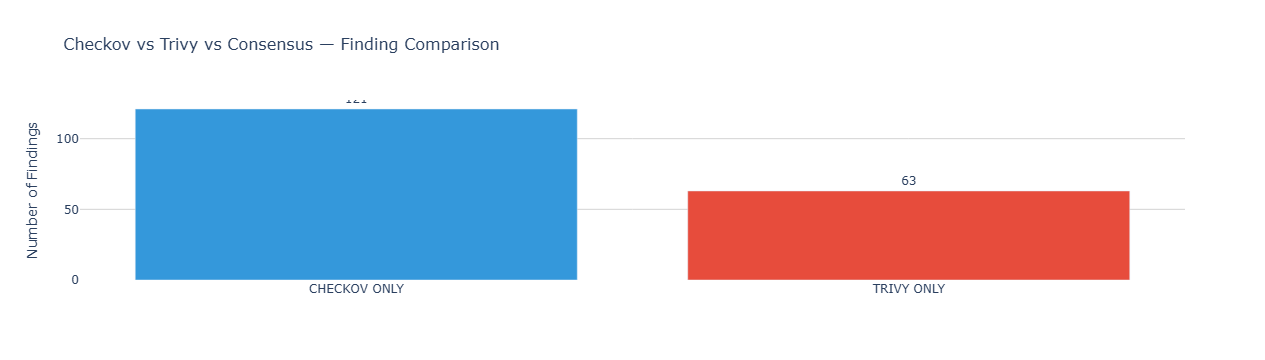

✅ Saved chart_consensus_comparison.html


In [23]:
source_summary = consensus_df.groupby('source').size().reset_index(name='count')

color_map = {
    'CONSENSUS':    '#2ecc71',
    'CHECKOV ONLY': '#3498db',
    'TRIVY ONLY':   '#e74c3c'
}

fig6 = px.bar(
    source_summary,
    x='source',
    y='count',
    text='count',
    color='source',
    color_discrete_map=color_map,
    title='Checkov vs Trivy vs Consensus — Finding Comparison',
    labels={'count': 'Number of Findings', 'source': ''}
)
fig6.update_traces(textposition='outside')
fig6.update_layout(
    height=450,
    plot_bgcolor='white',
    title_font_size=16,
    showlegend=False,
    yaxis=dict(showgrid=True, gridcolor='lightgrey')
)
fig6.show()
fig6.write_html("chart_consensus_comparison.html")
print("✅ Saved chart_consensus_comparison.html")

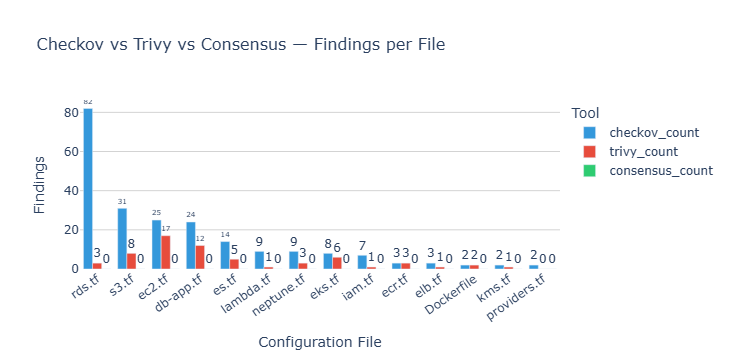

✅ Saved chart_consensus_by_file.html


In [24]:
gt_by_file = ground_truth.groupby('file').size().reset_index(name='consensus_count')
ck_by_file = df.groupby('file').size().reset_index(name='checkov_count')
tv_by_file = trivy_failed.groupby('file')['check_id_norm'].nunique().reset_index(name='trivy_count')

comparison = ck_by_file.merge(tv_by_file, on='file', how='outer').merge(gt_by_file, on='file', how='outer').fillna(0)
comparison = comparison.sort_values('checkov_count', ascending=False)

fig7 = px.bar(
    comparison.melt(id_vars='file', value_vars=['checkov_count','trivy_count','consensus_count'],
                    var_name='tool', value_name='count'),
    x='file',
    y='count',
    color='tool',
    barmode='group',
    text='count',
    title='Checkov vs Trivy vs Consensus — Findings per File',
    color_discrete_map={
        'checkov_count':   '#3498db',
        'trivy_count':     '#e74c3c',
        'consensus_count': '#2ecc71'
    },
    labels={'file': 'Configuration File', 'count': 'Findings', 'tool': 'Tool'}
)
fig7.update_traces(textposition='outside')
fig7.update_layout(
    height=500,
    plot_bgcolor='white',
    title_font_size=16,
    xaxis=dict(tickangle=-35),
    yaxis=dict(showgrid=True, gridcolor='lightgrey')
)
fig7.show()
fig7.write_html("chart_consensus_by_file.html")
print("✅ Saved chart_consensus_by_file.html")

In [25]:
total_consensus = len(ground_truth)
ck_only_count = len(consensus_df[consensus_df['source']=='CHECKOV ONLY'])
tv_only_count = len(consensus_df[consensus_df['source']=='TRIVY ONLY'])

print("=" * 58)
print("       TERRAGOAT AWS — FINAL GROUND TRUTH SUMMARY")
print("=" * 58)
print(f"  Checkov total findings         : {len(df)}")
print(f"  Trivy total findings           : {len(trivy_failed)}")
print(f"  ──────────────────────────────────────────────────")
print(f"  CONSENSUS ground truth         : {total_consensus}")
print(f"  Checkov-only (excluded)        : {ck_only_count}")
print(f"  Trivy-only (excluded)          : {tv_only_count}")
print(f"  ──────────────────────────────────────────────────")
print(f"  Ground truth status            : ✅ CONSENSUS (Checkov + Trivy)")
print(f"  Analysis tool 1                : Checkov v3.3.9")
print(f"  Analysis tool 2                : Trivy (latest)")
print(f"  Dataset                        : TerraGoat AWS Module")
print("=" * 58)

       TERRAGOAT AWS — FINAL GROUND TRUTH SUMMARY
  Checkov total findings         : 221
  Trivy total findings           : 115
  ──────────────────────────────────────────────────
  CONSENSUS ground truth         : 0
  Checkov-only (excluded)        : 121
  Trivy-only (excluded)          : 63
  ──────────────────────────────────────────────────
  Ground truth status            : ✅ CONSENSUS (Checkov + Trivy)
  Analysis tool 1                : Checkov v3.3.9
  Analysis tool 2                : Trivy (latest)
  Dataset                        : TerraGoat AWS Module
